In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/fptu-can-tho-olympic-ai-2026-vong-lo-i-warmup/label_mapping.json
/kaggle/input/competitions/fptu-can-tho-olympic-ai-2026-vong-lo-i-warmup/test_warmup/public_0079.jpg
/kaggle/input/competitions/fptu-can-tho-olympic-ai-2026-vong-lo-i-warmup/test_warmup/public_0018.jpg
/kaggle/input/competitions/fptu-can-tho-olympic-ai-2026-vong-lo-i-warmup/test_warmup/public_0032.jpg
/kaggle/input/competitions/fptu-can-tho-olympic-ai-2026-vong-lo-i-warmup/test_warmup/public_0049.jpg
/kaggle/input/competitions/fptu-can-tho-olympic-ai-2026-vong-lo-i-warmup/test_warmup/public_0215.jpg
/kaggle/input/competitions/fptu-can-tho-olympic-ai-2026-vong-lo-i-warmup/test_warmup/public_0064.jpg
/kaggle/input/competitions/fptu-can-tho-olympic-ai-2026-vong-lo-i-warmup/test_warmup/public_0016.jpg
/kaggle/input/competitions/fptu-can-tho-olympic-ai-2026-vong-lo-i-warmup/test_warmup/public_0114.jpg
/kaggle/input/competitions/fptu-can-tho-olympic-ai-2026-vong-lo-i-warmup/test_warmup/public_0090.jpg

--- Label Mapping ---
{
    "Bacterial Leaf Blight": 0,
    "Brown Spot": 1,
    "Healthy Rice Leaf": 2,
    "Leaf Blast": 3,
    "Leaf scald": 4,
    "Narrow Brown Leaf Spot": 5,
    "Rice Hispa": 6,
    "Sheath Blight": 7
}

--- 5 dòng đầu của DataFrame tập Train ---
              image_name  class_name  label  width  height  \
0   Leaf_scald  (85).jpg  Leaf scald      4   1600    1200   
1     aug_train_0470.jpg  Leaf scald      4   1200    1600   
2  Leaf_scald  (109).jpg  Leaf scald      4   1600    1200   
3  Leaf_scald  (166).jpg  Leaf scald      4   1600    1200   
4     aug_train_0654.jpg  Leaf scald      4   1200    1600   

                                                path  
0  /kaggle/input/competitions/fptu-can-tho-olympi...  
1  /kaggle/input/competitions/fptu-can-tho-olympi...  
2  /kaggle/input/competitions/fptu-can-tho-olympi...  
3  /kaggle/input/competitions/fptu-can-tho-olympi...  
4  /kaggle/input/competitions/fptu-can-tho-olympi...  


/tmp/ipykernel_58/635802404.py:59: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=class_counts.values, y=class_counts.index, palette='viridis')


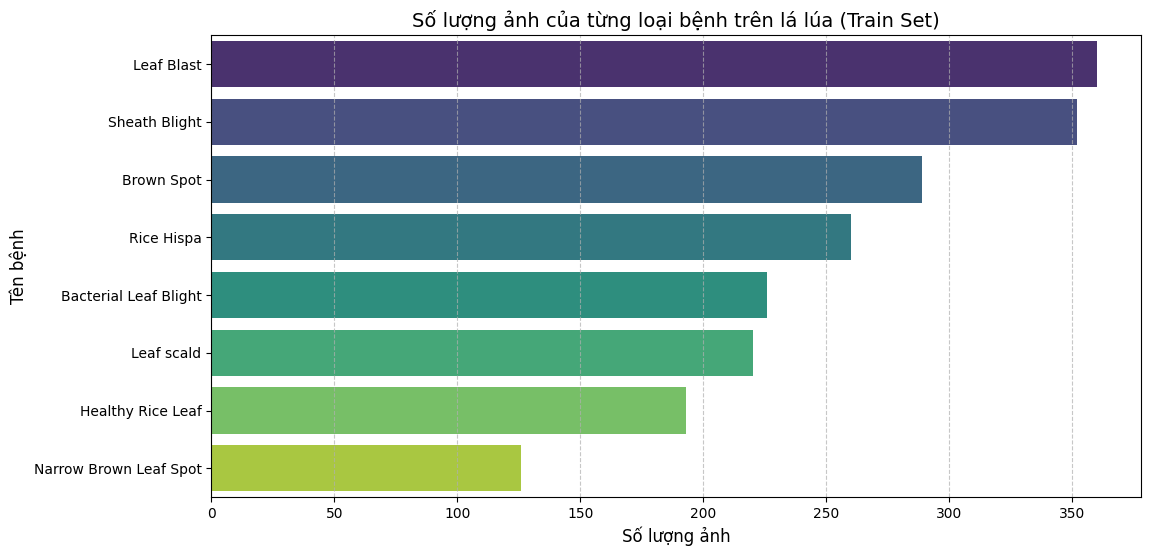


--- Thống kê chi tiết số lượng từng Class ---
                        Số lượng  Tỷ lệ (%)
class_name                                 
Leaf Blast                   360      17.77
Sheath Blight                352      17.37
Brown Spot                   289      14.26
Rice Hispa                   260      12.83
Bacterial Leaf Blight        226      11.15
Leaf scald                   220      10.86
Healthy Rice Leaf            193       9.53
Narrow Brown Leaf Spot       126       6.22

--- Thống kê kích thước ảnh (Width & Height) ---
             width       height
count  2026.000000  2026.000000
mean   1475.025666  1436.819348
std     405.431638   444.939306
min     427.000000   441.000000
25%    1200.000000  1200.000000
50%    1600.000000  1200.000000
75%    1600.000000  1600.000000
max    4000.000000  4000.000000

Các tổ hợp kích thước ảnh có trong tập dữ liệu:
    width  height  Số lượng
0     427    1322         2
1     431    1203         1
2     438    1074         2
3     570     

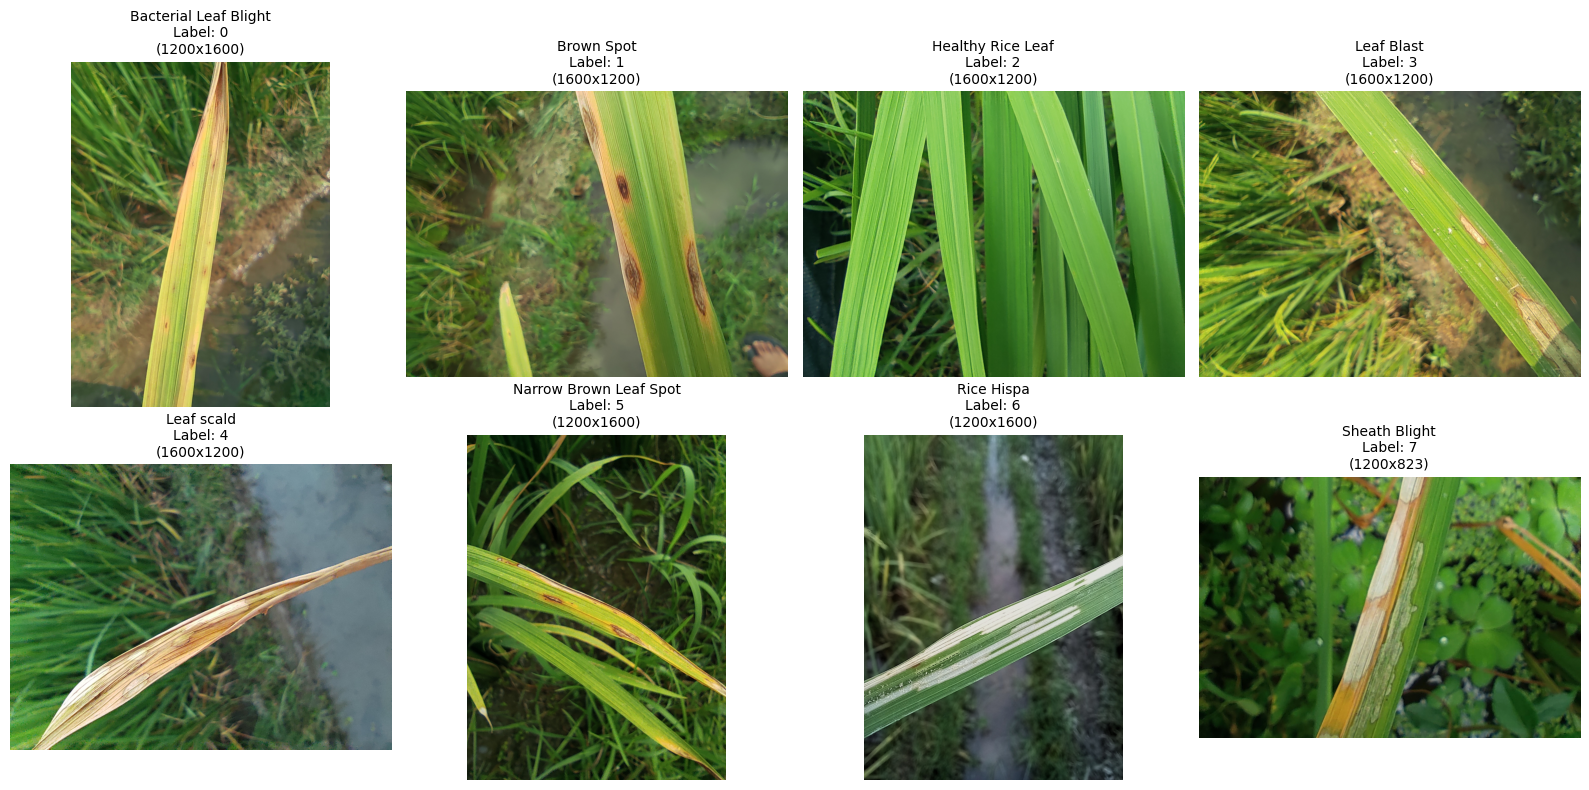

In [1]:
import os
import json
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

# 1. ĐỊNH NGHĨA ĐƯỜNG DẪN (Thay đổi cho đúng với thư mục của bạn)
DATA_DIR = "."  # Đường dẫn tới thư mục chứa dữ liệu
TRAIN_DIR = os.path.join(DATA_DIR, "/kaggle/input/competitions/fptu-can-tho-olympic-ai-2026-vong-lo-i-warmup/train")
TEST_DIR = os.path.join(DATA_DIR, "/kaggle/input/competitions/fptu-can-tho-olympic-ai-2026-vong-lo-i-warmup/test_warmup")  # Theo hình ảnh là test_warmup
LABEL_MAP_PATH = os.path.join(DATA_DIR, "/kaggle/input/competitions/fptu-can-tho-olympic-ai-2026-vong-lo-i-warmup/label_mapping.json")

# Đọc file label_mapping.json
with open(LABEL_MAP_PATH, 'r') as f:
    label_mapping = json.load(f)

print("--- Label Mapping ---")
print(json.dumps(label_mapping, indent=4))



# 2. THU THẬP THÔNG TIN TẬP TRAIN
train_data = []

for class_name in os.listdir(TRAIN_DIR):
    class_path = os.path.join(TRAIN_DIR, class_name)
    if os.path.isdir(class_path):
        for img_name in os.listdir(class_path):
            img_path = os.path.join(class_path, img_name)
            # Kiểm tra định dạng ảnh cơ bản
            if img_name.lower().endswith(('.png', '.jpg', '.jpeg', '.webp')):
                try:
                    with Image.open(img_path) as img:
                        width, height = img.size
                    
                    train_data.append({
                        "image_name": img_name,
                        "class_name": class_name,
                        "label": label_mapping.get(class_name, -1),
                        "width": width,
                        "height": height,
                        "path": img_path
                    })
                except Exception as e:
                    print(f"Lỗi khi đọc ảnh {img_name}: {e}")

df_train = pd.DataFrame(train_data)

print("\n--- 5 dòng đầu của DataFrame tập Train ---")
print(df_train.head())



# 3. TRỰC QUAN HÓA SỰ PHÂN BỐ CÁC LỚP (Class Distribution)
plt.figure(figsize=(12, 6))
# Đếm số lượng ảnh từng class và sắp xếp theo thứ tự nhãn trong json
class_counts = df_train['class_name'].value_counts()
sns.barplot(x=class_counts.values, y=class_counts.index, palette='viridis')

plt.title('Số lượng ảnh của từng loại bệnh trên lá lúa (Train Set)', fontsize=14)
plt.xlabel('Số lượng ảnh', fontsize=12)
plt.ylabel('Tên bệnh', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()

# In ra bảng số lượng cụ thể và tỷ lệ phần trăm
print("\n--- Thống kê chi tiết số lượng từng Class ---")
summary_df = df_train['class_name'].value_counts().to_frame(name='Số lượng')
summary_df['Tỷ lệ (%)'] = (summary_df['Số lượng'] / len(df_train) * 100).round(2)
print(summary_df)



# 4. PHÂN TÍCH KÍCH THƯỚC HÌNH ẢNH (Image Resolution)
print("\n--- Thống kê kích thước ảnh (Width & Height) ---")
print(df_train[['width', 'height']].describe())

# Kiểm tra xem có ảnh nào khác kích thước phổ biến không
unique_sizes = df_train.groupby(['width', 'height']).size().reset_index(name='Số lượng')
print("\nCác tổ hợp kích thước ảnh có trong tập dữ liệu:")
print(unique_sizes)



# 5. HIỂN THỊ ẢNH MINH HỌA CHO TỪNG LOẠI BỆNH
print("\n--- Đang hiển thị ảnh minh họa cho từng class... ---")
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

# Lấy 1 ảnh đại diện cho mỗi class dựa trên label mapping
for i, (class_name, label_id) in enumerate(label_mapping.items()):
    # Lọc ra các ảnh thuộc class này
    class_samples = df_train[df_train['class_name'] == class_name]
    
    if not class_samples.empty:
        # Lấy ảnh đầu tiên tìm được
        sample_row = class_samples.iloc[0]
        img = Image.open(sample_row['path'])
        
        axes[i].imshow(img)
        axes[i].set_title(f"{class_name}\nLabel: {label_id}\n({sample_row['width']}x{sample_row['height']})", fontsize=10)
    else:
        axes[i].text(0.5, 0.5, f"Không tìm thấy ảnh\n{class_name}", ha='center', va='center')
    
    axes[i].axis('off')

plt.tight_layout()
plt.show()

In [2]:
import os
import json
import cv2
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score
from sklearn.utils.class_weight import compute_class_weight
from imblearn.over_sampling import SMOTE

# =====================================================================
# 1. CẤU HÌNH ĐƯỜNG DẪN & THAM SỐ
# =====================================================================
DATA_DIR = "."  # Đường dẫn tới thư mục chứa dữ liệu của bạn
TRAIN_DIR = os.path.join(DATA_DIR, "/kaggle/input/competitions/fptu-can-tho-olympic-ai-2026-vong-lo-i-warmup/train")
LABEL_MAP_PATH = os.path.join(DATA_DIR, "/kaggle/input/competitions/fptu-can-tho-olympic-ai-2026-vong-lo-i-warmup/label_mapping.json")

# Kích thước ảnh chuẩn hóa cố định để giải quyết vấn đề ảnh to nhỏ lộn xộn trong EDA
IMG_SIZE = (128, 128) 

with open(LABEL_MAP_PATH, 'r') as f:
    label_mapping = json.load(f)

# =====================================================================
# 2. HÀM TRÍCH XUẤT ĐẶC TRƯNG TRUYỀN THỐNG (FEATURE EXTRACTION)
# =====================================================================
def extract_features(img_path):
    """
    Vì không dùng Deep Learning, ta phải tự trích xuất đặc trưng:
    - Màu sắc (Histogram màu) để phân biệt lá vàng/lá xanh/đốm nâu.
    - Kết cấu bệnh (Canny Edge) để nhận biết vết cháy, đốm sọc.
    """
    # Đọc ảnh bằng OpenCV (BGR)
    img = cv2.imread(img_path)
    if img is None:
        return None
    
    # Giải quyết triệt để kích thước lộn xộn bằng cách resize về cỡ cố định
    img = cv2.resize(img, IMG_SIZE)
    
    # Lấy đặc trưng Màu sắc: Chuyển sang HSV (tốt cho nhận diện màu hơn BGR)
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    # Tính Histogram cho cả 3 kênh màu (mỗi kênh chia làm 8 vùng)
    hist_h = cv2.calcHist([hsv], [0], None, [8], [0, 180])
    hist_s = cv2.calcHist([hsv], [1], None, [8], [0, 256])
    hist_v = cv2.calcHist([hsv], [2], None, [8], [0, 256])
    
    # Lấy đặc trưng Kết cấu/Hình dáng: Dùng thuật toán phát hiện cạnh Canny
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    edges = cv2.Canny(gray, 100, 200)
    # Thu nhỏ ma trận cạnh về một vector phẳng nhỏ hơn để làm đặc trưng
    edges_resized = cv2.resize(edges, (16, 16)).flatten()
    
    # Gom tất cả các đặc trưng lại thành 1 vector phẳng duy nhất
    color_features = np.concatenate([hist_h, hist_s, hist_v]).flatten()
    # Chuẩn hóa vector màu sắc
    color_features = color_features / (np.sum(color_features) + 1e-6) 
    
    final_features = np.concatenate([color_features, edges_resized / 255.0])
    return final_features

# =====================================================================
# 3. ĐỌC DỮ LIỆU VÀ TẠO TẬP ĐẶC TRƯNG (DATA LOADING)
# =====================================================================
print("--- Đang đọc dữ liệu và trích xuất đặc trưng truyền thống... ---")
X_list = []
y_list = []

for class_name, label_id in label_mapping.items():
    class_path = os.path.join(TRAIN_DIR, class_name)
    if os.path.isdir(class_path):
        print(f"Đang xử lý lớp: {class_name} (Nhãn: {label_id})")
        for img_name in os.listdir(class_path):
            if img_name.lower().endswith(('.png', '.jpg', '.jpeg', '.webp')):
                img_path = os.path.join(class_path, img_name)
                features = extract_features(img_path)
                if features is not None:
                    X_list.append(features)
                    y_list.append(label_id)

X = np.array(X_list)
y = np.array(y_list)
print(f"\nTổng số mẫu trích xuất thành công: {X.shape[0]} mẫu, mỗi mẫu có {X.shape[1]} đặc trưng.")

# Chia tập dữ liệu thành Train và Validation (Phân tầng Stratify để giữ nguyên tỉ lệ lệch lớp)
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# =====================================================================
# CHIẾN LƯỢC 1: SỬ DỤNG TĂNG CƯỜNG DỮ LIỆU SỐ BẰNG SMOTE (OVERSAMPLING)
# =====================================================================
print("\n--- Áp dụng kỹ thuật SMOTE cho 2 lớp thiểu số ---")
print("Số lượng mẫu trước SMOTE:", np.bincount(y_train))

# SMOTE tự sinh thêm dữ liệu nhân tạo cho các lớp ít mẫu (như nhãn 2 và 5) dựa trên các hàng xóm gần nhất
smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)

print("Số lượng mẫu sau SMOTE (các lớp đã cân bằng bằng nhau):", np.bincount(y_train_resampled))

# =====================================================================
# CHIẾN LƯỢC 2: TÍNH TOÁN TRỌNG SỐ LỚP (CLASS WEIGHTS)
# =====================================================================
# Tính toán trọng số lớp dựa trên tập dữ liệu gốc (cho trường hợp không dùng SMOTE)
classes = np.unique(y_train)
weights = compute_class_weight(class_weight='balanced', classes=classes, y=y_train)
class_weights_dict = {cls: weight for cls, weight in zip(classes, weights)}
print("\nTrọng số phạt (Class Weights) tính toán được từ tập gốc:")
for k, v in class_weights_dict.items():
    print(f" Nhãn {k}: {v:.4f}")

# =====================================================================
# 4. HUẤN LUYỆN MÔ HÌNH TRUYỀN THỐNG (RANDOM FOREST)
# =====================================================================
print("\n--- Bắt đầu huấn luyện mô hình Random Forest ---")

# LỰA CHỌN A: Dùng tập dữ liệu gốc kèm theo Class Weights phạt nặng lớp yếu
print("\n[Lựa chọn A]: Random Forest + Class Weights (Phạt nặng lớp thiểu số)")
model_weighted = RandomForestClassifier(
    n_estimators=200, 
    class_weight=class_weights_dict,  # Áp dụng trọng số vào thuật toán
    random_state=42, 
    n_jobs=-1
)
model_weighted.fit(X_train, y_train)
y_pred_w = model_weighted.predict(X_val)
print(f"Accuracy: {accuracy_score(y_val, y_pred_w):.4f}")
print(classification_report(y_val, y_pred_w, target_names=list(label_mapping.keys())))

# ---------------------------------------------------------------------
"""
# LỰA CHỌN B: Dùng tập dữ liệu đã qua xử lý SMOTE (Cân bằng số lượng mẫu)
print("\n[Lựa chọn B]: Random Forest + Dữ liệu đã qua SMOTE")
model_smote = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
model_smote.fit(X_train_resampled, y_train_resampled)
y_pred_s = model_smote.predict(X_val)
print(f"Accuracy: {accuracy_score(y_val, y_pred_s):.4f}")
print(classification_report(y_val, y_pred_s, target_names=list(label_mapping.keys())))
"""

--- Đang đọc dữ liệu và trích xuất đặc trưng truyền thống... ---
Đang xử lý lớp: Bacterial Leaf Blight (Nhãn: 0)
Đang xử lý lớp: Brown Spot (Nhãn: 1)
Đang xử lý lớp: Healthy Rice Leaf (Nhãn: 2)
Đang xử lý lớp: Leaf Blast (Nhãn: 3)
Đang xử lý lớp: Leaf scald (Nhãn: 4)
Đang xử lý lớp: Narrow Brown Leaf Spot (Nhãn: 5)
Đang xử lý lớp: Rice Hispa (Nhãn: 6)
Đang xử lý lớp: Sheath Blight (Nhãn: 7)

Tổng số mẫu trích xuất thành công: 2026 mẫu, mỗi mẫu có 280 đặc trưng.

--- Áp dụng kỹ thuật SMOTE cho 2 lớp thiểu số ---
Số lượng mẫu trước SMOTE: [181 231 154 288 176 101 208 281]
Số lượng mẫu sau SMOTE (các lớp đã cân bằng bằng nhau): [288 288 288 288 288 288 288 288]

Trọng số phạt (Class Weights) tính toán được từ tập gốc:
 Nhãn 0: 1.1188
 Nhãn 1: 0.8766
 Nhãn 2: 1.3149
 Nhãn 3: 0.7031
 Nhãn 4: 1.1506
 Nhãn 5: 2.0050
 Nhãn 6: 0.9736
 Nhãn 7: 0.7206

--- Bắt đầu huấn luyện mô hình Random Forest ---

[Lựa chọn A]: Random Forest + Class Weights (Phạt nặng lớp thiểu số)
Accuracy: 0.7759
          

'\n# LỰA CHỌN B: Dùng tập dữ liệu đã qua xử lý SMOTE (Cân bằng số lượng mẫu)\nprint("\n[Lựa chọn B]: Random Forest + Dữ liệu đã qua SMOTE")\nmodel_smote = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)\nmodel_smote.fit(X_train_resampled, y_train_resampled)\ny_pred_s = model_smote.predict(X_val)\nprint(f"Accuracy: {accuracy_score(y_val, y_pred_s):.4f}")\nprint(classification_report(y_val, y_pred_s, target_names=list(label_mapping.keys())))\n'

In [3]:
# =====================================================================
# 5. DỰ ĐOÁN TẬP TEST VÀ XUẤT FILE SUBMISSION KAGGLE
# =====================================================================
print("\n--- Bắt đầu quá trình dự đoán trên tập Test ---")

# Kiểm tra lại tên thư mục tập test (Theo ảnh Explorer của bạn là test_warmup)
# Nếu trên Kaggle hệ thống đổi tên thành test_images, bạn chỉ cần sửa lại biến TEST_DIR ở đầu file
test_images_list = []
test_features_list = []

# Đọc toàn bộ ảnh từ thư mục test
if os.path.exists(TEST_DIR):
    # Lấy danh sách và sắp xếp để đảm bảo thứ tự nhất quán (nếu cần)
    all_test_files = sorted(os.listdir(TEST_DIR))
    
    for img_name in all_test_files:
        if img_name.lower().endswith(('.png', '.jpg', '.jpeg', '.webp')):
            img_path = os.path.join(TEST_DIR, img_name)
            
            # Trích xuất đặc trưng giống hệt như đã làm với tập Train
            features = extract_features(img_path)
            
            if features is not None:
                test_images_list.append(img_name)
                test_features_list.append(features)
            else:
                # Trường hợp ảnh lỗi không đọc được, gán nhãn mặc định hoặc bỏ qua
                # Kaggle yêu cầu phải nộp đủ số lượng hàng, nên ta vẫn thêm tên ảnh vào
                test_images_list.append(img_name)
                # Tạo một mảng vector zero cùng kích thước để tránh lỗi crash code
                test_features_list.append(np.zeros(X.shape[1]))

    X_test = np.array(test_features_list)
    print(f"Đã xử lý xong {len(test_images_list)} ảnh tập Test.")

    # -----------------------------------------------------------------
    # Lựa chọn mô hình tốt nhất để dự đoán (Ví dụ chọn model_weighted)
    # -----------------------------------------------------------------
    print("Đang tiến hành dự đoán nhãn số (0 -> 7)...")
    test_predictions = model_weighted.predict(X_test)

    # Tạo DataFrame đúng chuẩn 2 cột theo yêu cầu của Kaggle
    submission_df = pd.DataFrame({
        "image_name": test_images_list,
        "label": test_predictions
    })

    # Xuất ra file CSV (Lưu ý: index=False để không sinh ra cột STT thừa)
    submission_path = "submission.csv"
    submission_df.to_csv(submission_path, index=False)
    
    print(f"\n🎉 Đã xuất file thành công: '{submission_path}'")
    print("--- 5 dòng đầu tiên của file submission ---")
    print(submission_df.head())
    print(f"\nTổng số dòng trong file (gồm cả header): {len(submission_df) + 1}")

else:
    print(f"❌ Không tìm thấy thư mục tập test tại đường dẫn: {TEST_DIR}")
    print("Vui lòng kiểm tra lại tên thư mục trên Kaggle (test_warmup hoặc test_images).")


--- Bắt đầu quá trình dự đoán trên tập Test ---
Đã xử lý xong 300 ảnh tập Test.
Đang tiến hành dự đoán nhãn số (0 -> 7)...

🎉 Đã xuất file thành công: 'submission.csv'
--- 5 dòng đầu tiên của file submission ---
        image_name  label
0  public_0001.jpg      6
1  public_0002.jpg      7
2  public_0003.jpg      3
3  public_0004.jpg      2
4  public_0005.jpg      4

Tổng số dòng trong file (gồm cả header): 301
